***CHECKING IF THE BUILT MLP WORKS***

In [ ]:
import sys; sys.path.insert(0, "../src")
from protgen.models.mlp import MLP
import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

Now that the mlp.py contains an actual Architecture we will now test if it is working. Initial approach uses 128 hidden units. Each embedding is 24 long

Adding same structure used in the Introduction:

In [15]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

# Val loader
val_loader = DataLoader(val_data, batch_size=32, shuffle=True)

# MLP
mlp = MLP()

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

In [16]:
print(mlp)

MLP(
  (embedding): Embedding(23, 24, padding_idx=0)
  (net): Sequential(
    (0): Linear(in_features=72, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=23, bias=True)
  )
)


In [8]:
print(list(mlp.named_parameters()))

[('embedding.weight', Parameter containing:
tensor([[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
        [ 3.6922e-01,  1.1691e+00, -4.9908e-01,  1.3296e+00, -2.7892e-01,
          8.2929e-01,  4.4105e-01,  6.7290e-01,  3.2369e-01,  2.3259e-01,
          1.9330e+00,  3.9602e-01, -1.2751e-01,  9.3326e-01, -6.8214e-01,
         -3.9475e-01,  2.3331e-01, -3.7765e-01,  1.4750e+00,  5.0521e-01,
          2.5990e-01,  8.2951e-02, -5.9259e-01, -7.9033e-01],
        [ 3.6948e-01, -5.7663e-01, -2.5121e-01, -1.4262e+00,  3.0310e-01,
         -6.7156e-01, -3.3400e-01,  4.4713e-01,  1.6549e-01,  7.7800e-01,
         -1.0554e+00, -2.2278e+00,  1.9047e+00,  5.6896e-01, -2.7210e+00,
          1.4064e+

In [9]:
train_data.df

,sequence,family
0,MIKKQFNIIKNTGFARPATLLVKLSQRFTSDISLEYQGKTINLKHS...,HPr
1,MNKHELITRISEKSGMTKKDVESVLNGFMDEVTDALGSGNKVQLIG...,HU
2,MTQRFEDTFLIQNKLGLHARAASVLAELSAQFDANITLFQGSKEAE...,HPr
3,MNKTELILRIAEETGFSRKNVELGLNAAINLITKALTEEEKVQIVG...,HU
4,MVERKAVIKNEAGIHCRPTAVITQEAAKVDAVIMILSPGGTCQLGS...,HPr
...,...,...
16015,MTKADIINEIANETGVAKKDVTVVVESFMATIKDSLLEKRECVYLR...,HU
16016,MSRLSRQVTIVNQKGLHARASAKFVTFVSRLPEGLKVEVEKDGQCV...,HPr
16017,MNKSDLINHVAAETGLTKADSGFALEAVLEGITKSLRKGDTVTLTG...,HU
16018,MTLTKAELADLLFEKVGLNKREAKDMVEAFFEEIRNALERGEGVKL...,HU


In [10]:
val_data.df

,sequence,family
0,MNKADFVKHVAQQHQCTQIEAEKTIDMFTSSVIDAMGKGNEISLVG...,HU
1,MSERKATIASRVGLHARPASIFAAAVGELPIEVTIGLEADPVEDAM...,HPr
2,MNKSQLIDKIAAGAELSKADAGRALDAFIGAVTDALKEGDSVALVG...,HU
3,MNKSELVDKMAEKSGLSKKDSDKALNAMLESVEEALTSGDKVQLIG...,HU
4,MNKTELIDHIASKADISKAAAGRTLDALIGAVKTTLKKGGTVTLVG...,HU
...,...,...
1996,MDNRSRREAPEAVDTHGYYKAEIEVTHGFGLHARPSVIFTRLAKSF...,HPr
1997,MNKSELIDAIAASADIPKAVAGRALDAVIDSVTGALKAGDSVVLVG...,HU
1998,MSEHESAGRKLVSVDFEIFGYVQGVCFRMYTEREGLRLGLVGWVKN...,AcyP
1999,MNKSELIDAIAESADISKAAAGRALDAMTNTITGALKNDDQVTLIG...,HU


In [11]:
test_data.df

,sequence,family
0,MTKAEVIVAIADKTGVDKASVSTTLESFFEIVKDTLAQGDAVYVRG...,HU
1,MERVTAVARGRVQGVGYRYYVSECAHATGIHGWVKNEPDGTVRIVA...,AcyP
2,MPQSSRTVLIQNRLGLHARAAVKLVELAQSFEAVLTIQNQEGKEAT...,HPr
3,MKHLNLKIHGKVQGVFFREKTKQLAQELGLNGYVKNTSDNCVEVVV...,AcyP
4,MTDRTRAHVYVSGKVQGVYFRATTREEAREQGVDGWVRNLDDGRVE...,AcyP
...,...,...
1996,MNKSELIQAVAERSELTKKDAGSAIQAAFDIISETLEKGETVQLIG...,HU
1997,MANKAELIDSVASKTGLTKKDATSAVDAVFETIQDNLSEGNKVQLI...,HU
1998,MPKLERQVTICNKLGLHARAATKLVVLASEFDASITLIQGEKQASA...,HPr
1999,MAAASAGGPSDPPTPQQSSPTKAVRVVVKGRVQGVFFRDWTVETAR...,AcyP


***CHECK WINDOWING IS WORKING - add print(window_3s) in forward***

In [ ]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

# Val loader
val_loader = DataLoader(val_data, batch_size=32, shuffle=True)

# MLP
mlp = MLP()

***TRAINING***

In [35]:
def train_one(lr, num_hidden, num_epochs):
    torch.manual_seed(42)
    mlp = MLP(num_hidden=num_hidden)
    loss_fn = nn.CrossEntropyLoss(ignore_index = -1)
    optimizer = optim.SGD(mlp.parameters(), lr= lr)    
    val_losses = []
    train_losses = []

    for epoch in range(num_epochs):
        mlp.train()
        total = 0
        for x, x_shifted, y, length in train_loader:
            optimizer.zero_grad()
            out = mlp(x)
            loss = loss_fn(out.transpose(1, 2), x_shifted)
            loss.backward()
            optimizer.step()
            total += loss.item()
        train_loss = total / len(train_loader)
        train_losses.append(train_loss)

        # Validation
        mlp.eval()
        total = 0
        with torch.no_grad():
            for x, x_shifted, y, length in val_loader:
                out = mlp(x)
                loss = loss_fn(out.transpose(1, 2), x_shifted)
                total += loss.item()
        val_loss = total / len(val_loader)
        val_losses.append(val_loss)

        print(f"Epoch {epoch+1}/{num_epochs} | train {train_loss:.4f} | val {val_loss:.4f}")
    return val_losses

lr_list = [0.01, 0.05, 0.1]
num_hidden_list = [64,128,256]
results = {}

for lr in lr_list:
    for num_hidden in num_hidden_list:
        print (f" lr = {lr}, num_hidden = {num_hidden}")
        results[(lr, num_hidden)] = train_one(lr,num_hidden, 20)

 lr = 0.01, num_hidden = 64
Epoch 1/20 | train 2.9880 | val 2.8698
Epoch 2/20 | train 2.8329 | val 2.7864
Epoch 3/20 | train 2.7780 | val 2.7471
Epoch 4/20 | train 2.7468 | val 2.7209
Epoch 5/20 | train 2.7251 | val 2.7022
Epoch 6/20 | train 2.7091 | val 2.6874
Epoch 7/20 | train 2.6966 | val 2.6755
Epoch 8/20 | train 2.6863 | val 2.6652
Epoch 9/20 | train 2.6775 | val 2.6571
Epoch 10/20 | train 2.6699 | val 2.6495
Epoch 11/20 | train 2.6631 | val 2.6423
Epoch 12/20 | train 2.6569 | val 2.6362
Epoch 13/20 | train 2.6513 | val 2.6306
Epoch 14/20 | train 2.6459 | val 2.6249
Epoch 15/20 | train 2.6409 | val 2.6203
Epoch 16/20 | train 2.6362 | val 2.6151
Epoch 17/20 | train 2.6315 | val 2.6107
Epoch 18/20 | train 2.6272 | val 2.6062
Epoch 19/20 | train 2.6229 | val 2.6017
Epoch 20/20 | train 2.6188 | val 2.5976
 lr = 0.01, num_hidden = 128
Epoch 1/20 | train 2.9797 | val 2.8399
Epoch 2/20 | train 2.8078 | val 2.7581
Epoch 3/20 | train 2.7541 | val 2.7197
Epoch 4/20 | train 2.7241 | val 2.6

RUnning on Adam optimizer

In [42]:
def train_one(lr, num_hidden, num_epochs):
    torch.manual_seed(42)
    mlp = MLP(num_hidden=num_hidden)
    loss_fn = nn.CrossEntropyLoss(ignore_index = -1)
    optimizer = optim.Adam(mlp.parameters(), lr= lr)    
    val_losses = []
    train_losses = []

    for epoch in range(num_epochs):
        mlp.train()
        total = 0
        for x, x_shifted, y, length in train_loader:
            optimizer.zero_grad()
            out = mlp(x)
            loss = loss_fn(out.transpose(1, 2), x_shifted)
            loss.backward()
            optimizer.step()
            total += loss.item()
        train_loss = total / len(train_loader)
        train_losses.append(train_loss)

        # Validation
        mlp.eval()
        total = 0
        with torch.no_grad():
            for x, x_shifted, y, length in val_loader:
                out = mlp(x)
                loss = loss_fn(out.transpose(1, 2), x_shifted)
                total += loss.item()
        val_loss = total / len(val_loader)
        val_losses.append(val_loss)

        print(f"Epoch {epoch+1}/{num_epochs} | train {train_loss:.4f} | val {val_loss:.4f}")
    return val_losses

lr_list = [0.0003, 0.001, 0.003]
num_hidden_list = [64,128,256]
results_adam = {}

for lr in lr_list:
    for num_hidden in num_hidden_list:
        print (f" lr = {lr}, num_hidden = {num_hidden}")
        results_adam[(lr, num_hidden)] = train_one(lr,num_hidden, 20)

 lr = 0.0003, num_hidden = 64
Epoch 1/20 | train 2.7536 | val 2.6230
Epoch 2/20 | train 2.6031 | val 2.5532
Epoch 3/20 | train 2.5425 | val 2.5039
Epoch 4/20 | train 2.4964 | val 2.4710
Epoch 5/20 | train 2.4624 | val 2.4507
Epoch 6/20 | train 2.4378 | val 2.4353
Epoch 7/20 | train 2.4199 | val 2.4264
Epoch 8/20 | train 2.4067 | val 2.4177
Epoch 9/20 | train 2.3962 | val 2.4144
Epoch 10/20 | train 2.3879 | val 2.4103
Epoch 11/20 | train 2.3813 | val 2.4093
Epoch 12/20 | train 2.3757 | val 2.4077
Epoch 13/20 | train 2.3712 | val 2.4062
Epoch 14/20 | train 2.3672 | val 2.4027
Epoch 15/20 | train 2.3635 | val 2.4030
Epoch 16/20 | train 2.3605 | val 2.4021
Epoch 17/20 | train 2.3578 | val 2.4017
Epoch 18/20 | train 2.3555 | val 2.3995
Epoch 19/20 | train 2.3532 | val 2.3985
Epoch 20/20 | train 2.3512 | val 2.3992
 lr = 0.0003, num_hidden = 128
Epoch 1/20 | train 2.7179 | val 2.5866
Epoch 2/20 | train 2.5673 | val 2.5144
Epoch 3/20 | train 2.4919 | val 2.4595
Epoch 4/20 | train 2.4367 | val

In [43]:
def best_run(res):
    best_loss = 999
    for key, val_losses in res.items():
        if min(val_losses) < best_loss:
            best_loss = min(val_losses)
            best_key = key
    return best_key

sgd_key = best_run(results)
adam_key = best_run(results_adam)

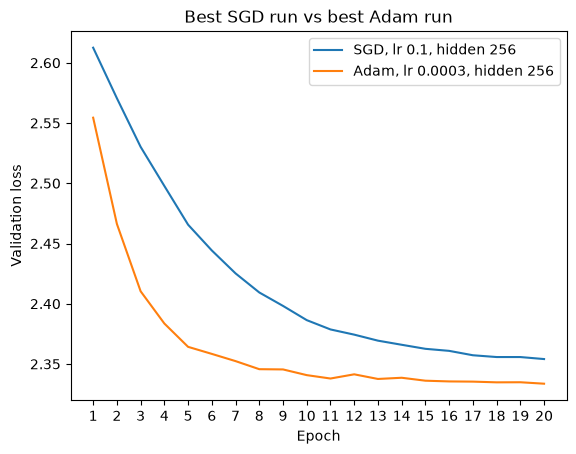

In [ ]:
epochs = range(1, 21)  # 20 epochs; change if you trained a different number

plt.figure()
plt.plot(epochs, results[sgd_key], label=f"SGD, lr {sgd_key[0]}, hidden {sgd_key[1]}")
plt.plot(epochs, results_adam[adam_key], label=f"Adam, lr {adam_key[0]}, hidden {adam_key[1]}")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Best SGD run vs best Adam run")
plt.xticks(epochs)
plt.legend()
plt.show()

In [45]:
rows = []
for (lr, hidden), val_losses in results.items():
    rows.append({"optimizer": "SGD", "lr": lr, "hidden": hidden, "best_val_loss": min(val_losses)})
for (lr, hidden), val_losses in results_adam.items():
    rows.append({"optimizer": "Adam", "lr": lr, "hidden": hidden, "best_val_loss": min(val_losses)})

df = pd.DataFrame(rows)
print(df.pivot_table(index=["optimizer", "lr"], columns="hidden", values="best_val_loss").round(3))

hidden              64     128    256
optimizer lr                         
Adam      0.0003  2.398  2.364  2.334
          0.0010  2.391  2.354  2.334
          0.0030  2.387  2.362  2.336
SGD       0.0100  2.598  2.584  2.569
          0.0500  2.444  2.413  2.387
          0.1000  2.409  2.378  2.354
